# Import Libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib


# Data Loading

In [ ]:
df = pd.read_csv('tlast3.csv')
print(df.info())
print(df.head())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 162567 entries, 0 to 162566
Data columns (total 11 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   date                    162285 non-null  object 
 1   source                  162285 non-null  object 
 2   destination             162285 non-null  object 
 3   distance_km             160635 non-null  float64
 4   congestion_index        160635 non-null  float64
 5   time_of_day             160430 non-null  object 
 6   weather                 160338 non-null  object 
 7   day_of_week             162285 non-null  object 
 8   festival                54757 non-null   object 
 9   actual_travel_time_min  160635 non-null  float64
 10  road_type               159424 non-null  object 
dtypes: float64(3), object(8)
memory usage: 13.6+ MB
None
         date    source              destination  distance_km  \
0  15-07-2022     Powai                   Airoli    14.256019   

# Data Preprocessing

In [3]:
print('Missing values:\n', df.isnull().sum())


Missing values:
 date                         282
source                       282
destination                  282
distance_km                 1932
congestion_index            1932
time_of_day                 2137
weather                     2229
day_of_week                  282
festival                  107810
actual_travel_time_min      1932
road_type                   3143
dtype: int64


# Feature Engineering

In [4]:
# Drop festival column
df.drop(columns=['festival'], inplace=True)

# Fill missing numerical values with median
num_cols = ['distance_km', 'congestion_index', 'actual_travel_time_min']
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with mode
cat_cols = ['weather', 'road_type', 'time_of_day']
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# --- Extract date features ---
# day_of_week and month are derived from date
# day_of_month is skipped — too noisy without multiple years of data
df['date']        = pd.to_datetime(df['date'], errors='coerce')
df['day_of_week'] = df['date'].dt.day_name()  # overwrite CSV column with date-derived value
df['month']       = df['date'].dt.month       # 1=Jan ... 10=Oct(Dashain) ... 12=Dec

# --- Parse time of day ---
time_parsed       = pd.to_datetime(df['time_of_day'], format='%H:%M', errors='coerce')
df['time_in_hours'] = time_parsed.dt.hour + time_parsed.dt.minute / 60

# --- One-hot encode categoricals ---
# drop_first=True removes baseline: congested, Friday, Clear
df = pd.get_dummies(
    df,
    columns=['road_type', 'day_of_week', 'weather'],
    drop_first=True,
    dtype=int
)

df.dropna(inplace=True)

print('Columns after encoding:')
print(df.columns.tolist())


C:\Users\Ronish\AppData\Local\Temp\ipykernel_3952\2636935567.py:17: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['date']        = pd.to_datetime(df['date'], errors='coerce')


Columns after encoding:
['date', 'source', 'destination', 'distance_km', 'congestion_index', 'time_of_day', 'actual_travel_time_min', 'month', 'time_in_hours', 'road_type_freeway', 'road_type_urban', 'day_of_week_Monday', 'day_of_week_Saturday', 'day_of_week_Sunday', 'day_of_week_Thursday', 'day_of_week_Tuesday', 'day_of_week_Wednesday', 'weather_Cloudy', 'weather_Fog', 'weather_Heavy Rain', 'weather_Rain', 'weather_Storm']


# Outlier Detection & Removal

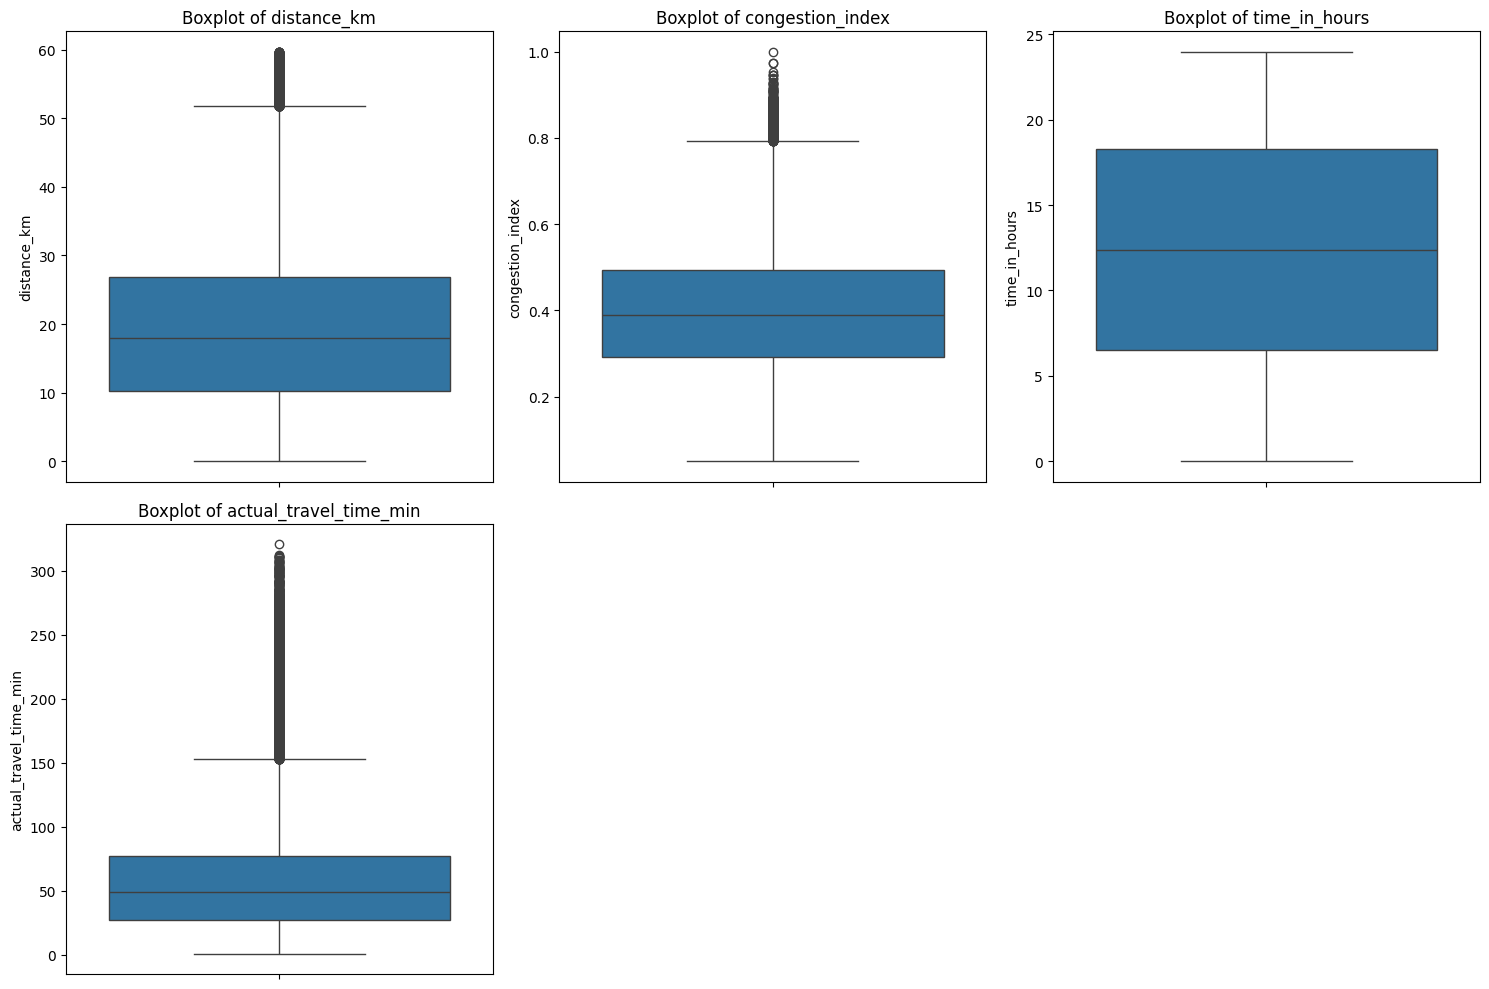

Shape after outlier removal: (156263, 22)


In [5]:
numerical_cols = ['distance_km', 'congestion_index', 'time_in_hours', 'actual_travel_time_min']

plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.savefig('traffic-outliers.png')
plt.show()

Q1  = df[numerical_cols].quantile(0.25)
Q3  = df[numerical_cols].quantile(0.75)
IQR = Q3 - Q1
df  = df[~((df[numerical_cols] < (Q1 - 1.5 * IQR)) |
           (df[numerical_cols] > (Q3 + 1.5 * IQR))).any(axis=1)]

print('Shape after outlier removal:', df.shape)


# Train / Test Split

In [6]:
X = df.drop(columns=[
    'actual_travel_time_min',  # target
    'date',                    # raw date — extracted month + day_of_week from it
    'source',                  # text address — useless to model
    'destination',             # text address — useless to model
    'time_of_day',             # raw time string — converted to time_in_hours
])
y = df['actual_travel_time_min']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('Training shape:', X_train.shape)
print('Test shape:    ', X_test.shape)
print('\nFinal features used by model:')
for col in X.columns:
    print(' -', col)


Training shape: (125010, 17)
Test shape:     (31253, 17)

Final features used by model:
 - distance_km
 - congestion_index
 - month
 - time_in_hours
 - road_type_freeway
 - road_type_urban
 - day_of_week_Monday
 - day_of_week_Saturday
 - day_of_week_Sunday
 - day_of_week_Thursday
 - day_of_week_Tuesday
 - day_of_week_Wednesday
 - weather_Cloudy
 - weather_Fog
 - weather_Heavy Rain
 - weather_Rain
 - weather_Storm


# Random Forest — GridSearchCV

In [7]:
rf = RandomForestRegressor(random_state=42)

param_grid = {
    'n_estimators':     [100, 200, 300],
    'max_depth':        [None, 10, 20],
    'min_samples_leaf': [1, 3]
}

grid_search = GridSearchCV(rf, param_grid, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)
grid_search.fit(X_train, y_train)

model = grid_search.best_estimator_
model.fit(X_train, y_train)

print('Best params:', grid_search.best_params_)
print('Best CV RMSE:', -grid_search.best_score_)


Best params: {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 300}
Best CV RMSE: 8.505102452123317


In [8]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(model, X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error')
print(f'CV scores: {-cv_scores}')
print(f'CV RMSE:   {-cv_scores.mean():.2f}')


CV scores: [8.45037225 8.55739678 8.49572326 8.53072462 8.58358084]
CV RMSE:   8.52


# Model Evaluation

In [9]:
y_train_pred = model.predict(X_train)
y_test_pred  = model.predict(X_test)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse  = np.sqrt(mean_squared_error(y_test,  y_test_pred))
train_mae  = mean_absolute_error(y_train, y_train_pred)
test_mae   = mean_absolute_error(y_test,  y_test_pred)
train_r2   = r2_score(y_train, y_train_pred)
test_r2    = r2_score(y_test,  y_test_pred)

print('Random Forest Performance:')
print(f'  Train RMSE: {train_rmse:.2f}  |  Test RMSE: {test_rmse:.2f}')
print(f'  Train MAE:  {train_mae:.2f}  |  Test MAE:  {test_mae:.2f}')
print(f'  Train R²:   {train_r2:.4f}  |  Test R²:  {test_r2:.4f}')


Random Forest Performance:
  Train RMSE: 3.93  |  Test RMSE: 8.42
  Train MAE:  3.12  |  Test MAE:  6.59
  Train R²:   0.9864  |  Test R²:  0.9386


In [10]:
joblib.dump(model, '91.pkl')
print('Saved: traffic_congestion_model_v2.pkl')
print('Features the model expects:', model.feature_names_in_.tolist())


Saved: traffic_congestion_model_v2.pkl
Features the model expects: ['distance_km', 'congestion_index', 'month', 'time_in_hours', 'road_type_freeway', 'road_type_urban', 'day_of_week_Monday', 'day_of_week_Saturday', 'day_of_week_Sunday', 'day_of_week_Thursday', 'day_of_week_Tuesday', 'day_of_week_Wednesday', 'weather_Cloudy', 'weather_Fog', 'weather_Heavy Rain', 'weather_Rain', 'weather_Storm']


# Visualizations

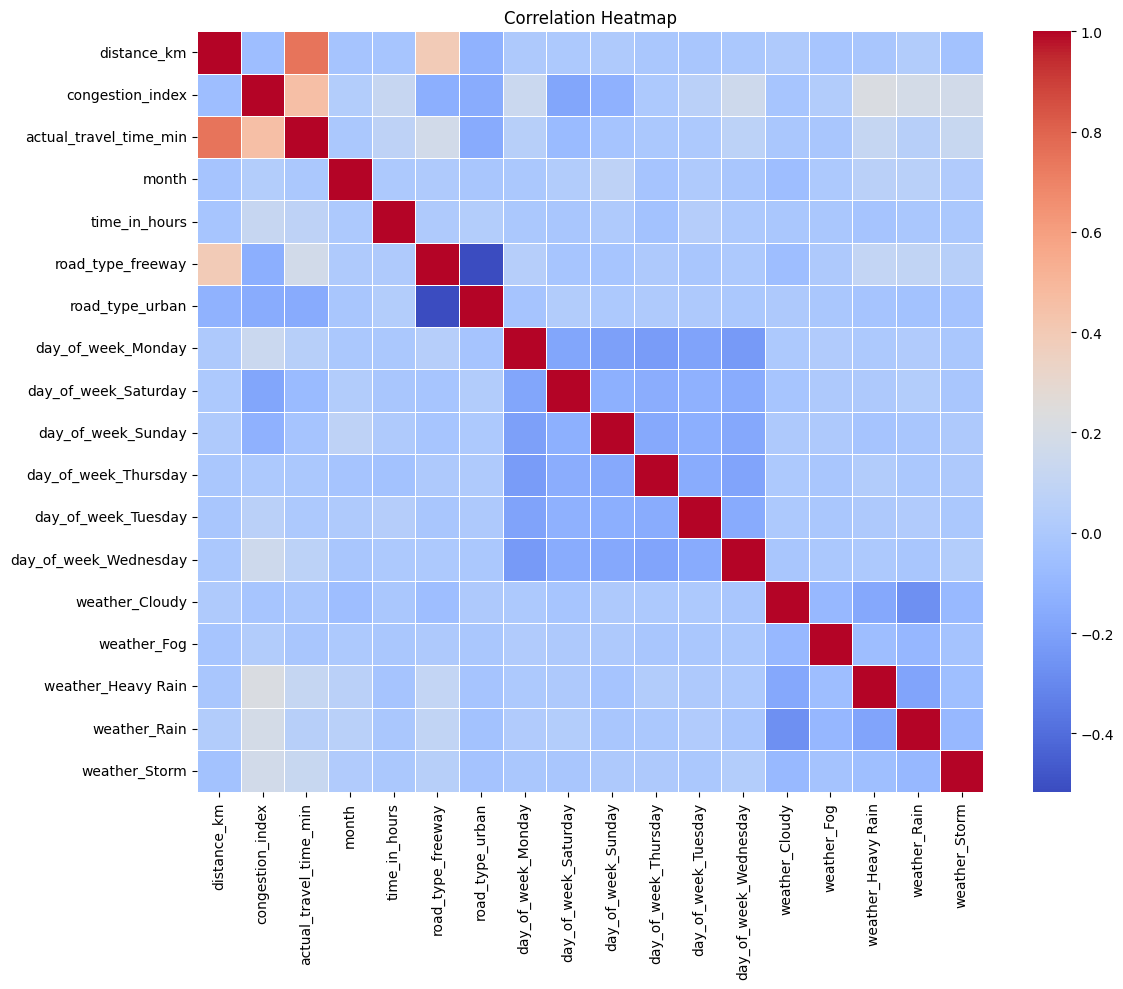

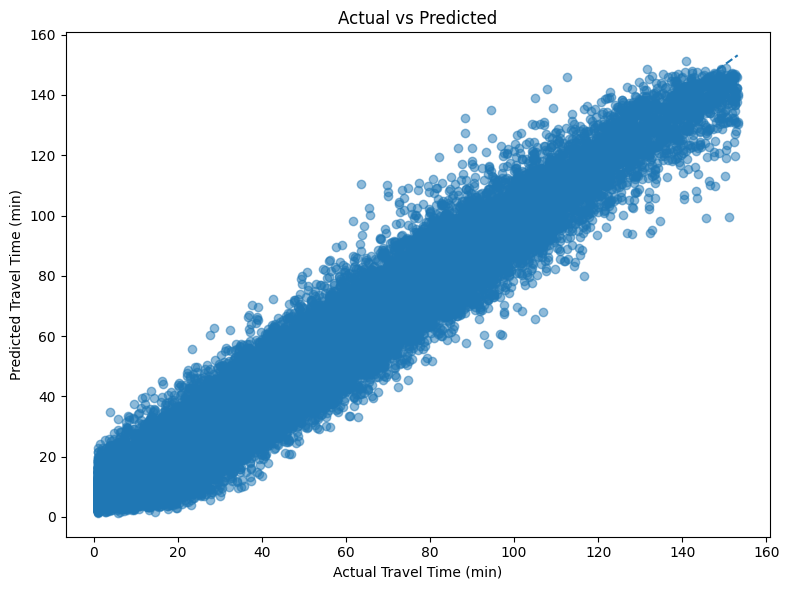

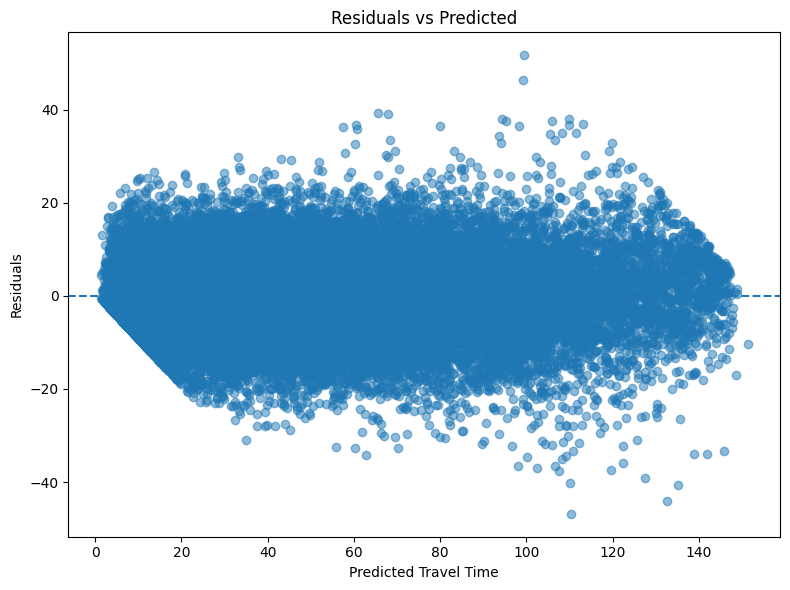

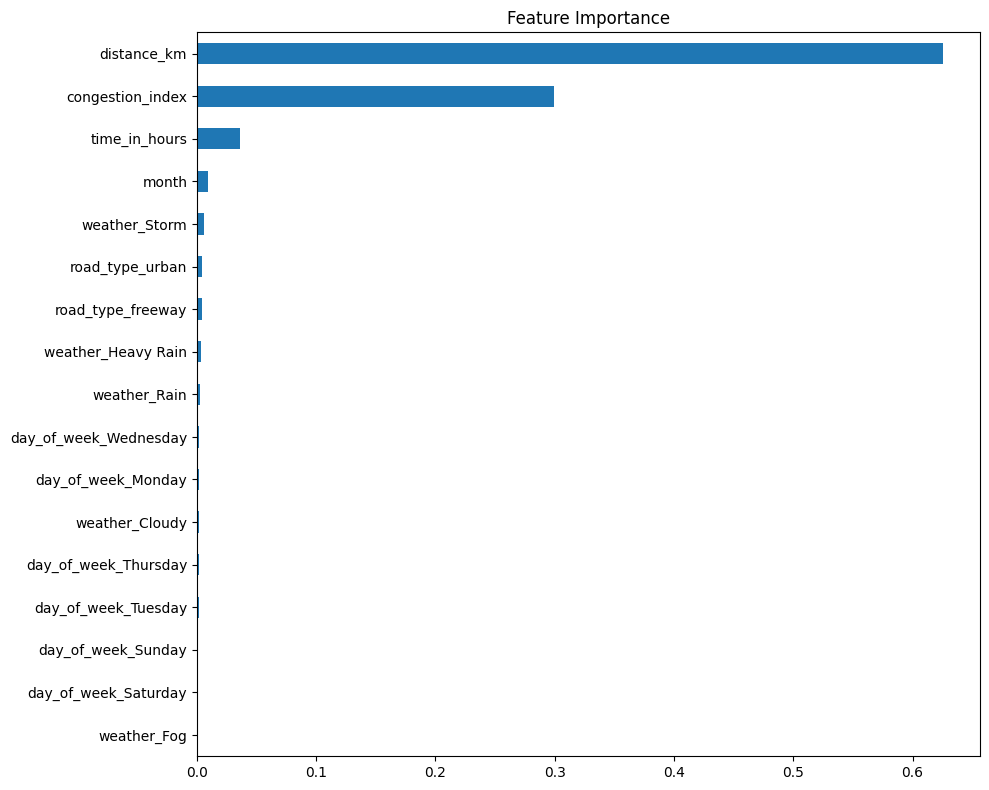

In [11]:
# Correlation Heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(numeric_only=True), annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig('1_correlation_heatmap.png')
plt.show()

# Actual vs Predicted
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_test_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], linestyle='--')
plt.xlabel('Actual Travel Time (min)')
plt.ylabel('Predicted Travel Time (min)')
plt.title('Actual vs Predicted')
plt.tight_layout()
plt.savefig('2_actual_vs_predicted.png')
plt.show()

# Residuals
plt.figure(figsize=(8, 6))
residuals = y_test - y_test_pred
plt.scatter(y_test_pred, residuals, alpha=0.5)
plt.axhline(y=0, linestyle='--')
plt.xlabel('Predicted Travel Time')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted')
plt.tight_layout()
plt.savefig('3_residual_plot.png')
plt.show()

# Feature Importance
plt.figure(figsize=(10, 8))
pd.Series(model.feature_importances_, index=X_train.columns).sort_values().plot(kind='barh')
plt.title('Feature Importance')
plt.tight_layout()
plt.savefig('4_feature_importance.png')
plt.show()


# Model Comparison

# Model Training — Linear Regression & Gradient Boosting

In [12]:
import os
os.makedirs('results', exist_ok=True)

# ── Linear Regression ─────────────────────────────────────────────────────────
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr    = lr.predict(X_test)
test_rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
test_mae_lr  = mean_absolute_error(y_test, y_pred_lr)
test_r2_lr   = r2_score(y_test, y_pred_lr)

# ── Gradient Boosting ─────────────────────────────────────────────────────────
gb = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb.fit(X_train, y_train)
y_pred_gb    = gb.predict(X_test)
test_rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
test_mae_gb  = mean_absolute_error(y_test, y_pred_gb)
test_r2_gb   = r2_score(y_test, y_pred_gb)

print(f"{'Model':<22} {'RMSE':>8} {'MAE':>8} {'R²':>8}")
print("-" * 50)
print(f"{'Linear Regression':<22} {test_rmse_lr:>8.2f} {test_mae_lr:>8.2f} {test_r2_lr:>8.4f}")
print(f"{'Gradient Boosting':<22} {test_rmse_gb:>8.2f} {test_mae_gb:>8.2f} {test_r2_gb:>8.4f}")
print(f"{'Random Forest':<22} {test_rmse:>8.2f} {test_mae:>8.2f} {test_r2:>8.4f}")


Model                      RMSE      MAE       R²
--------------------------------------------------
Linear Regression         13.94    10.75   0.8314
Gradient Boosting          9.82     7.63   0.9164
Random Forest              8.42     6.59   0.9386


# Results & Analysis — Linear Regression

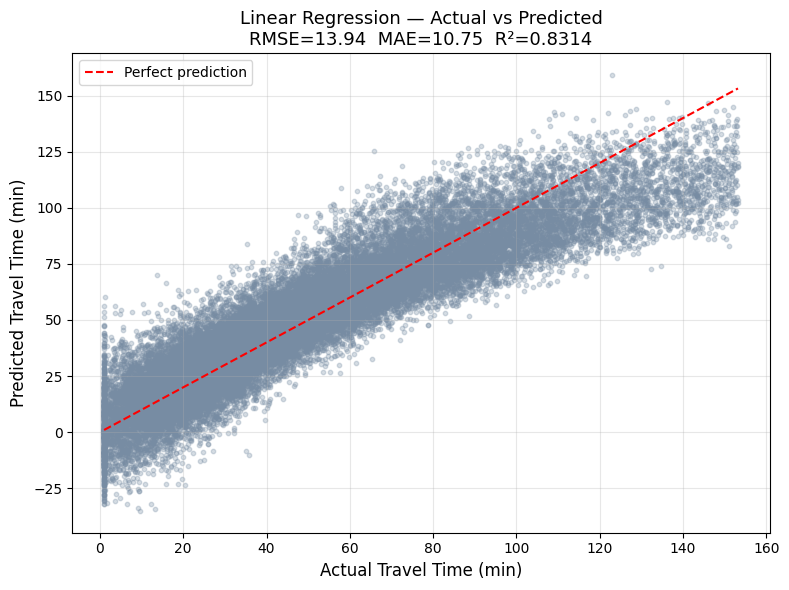

Saved: results/lr_actual_vs_predicted.png


In [13]:
# ── Linear Regression: Actual vs Predicted ────────────────────────────────────
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_lr, alpha=0.3, s=10, color='#778CA3')
mn, mx = y_test.min(), y_test.max()
plt.plot([mn, mx], [mn, mx], 'r--', linewidth=1.5, label='Perfect prediction')
plt.xlabel('Actual Travel Time (min)', fontsize=12)
plt.ylabel('Predicted Travel Time (min)', fontsize=12)
plt.title(f'Linear Regression — Actual vs Predicted\nRMSE={test_rmse_lr:.2f}  MAE={test_mae_lr:.2f}  R²={test_r2_lr:.4f}', fontsize=13)
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig('results/lr_actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: results/lr_actual_vs_predicted.png")


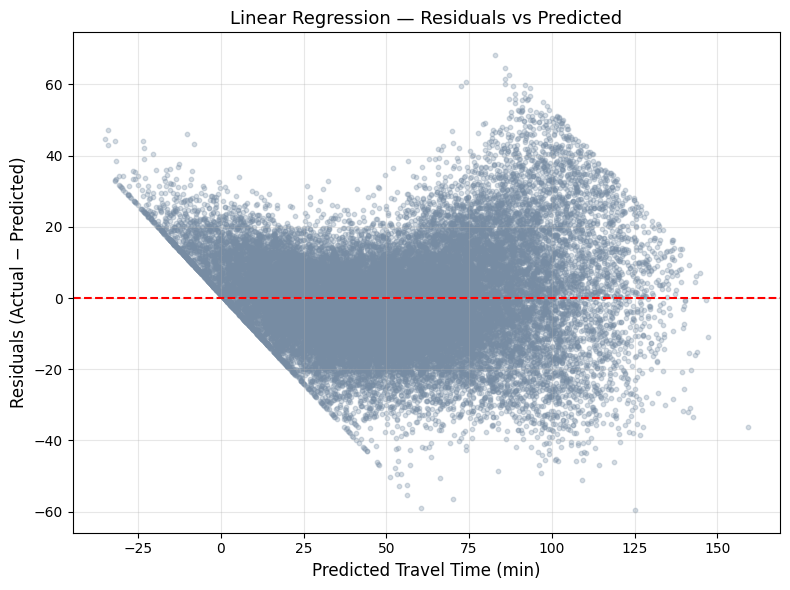

Saved: results/lr_residuals.png


In [14]:
# ── Linear Regression: Residuals ─────────────────────────────────────────────
residuals_lr = y_test - y_pred_lr
plt.figure(figsize=(8, 6))
plt.scatter(y_pred_lr, residuals_lr, alpha=0.3, s=10, color='#778CA3')
plt.axhline(0, color='red', linestyle='--', linewidth=1.5)
plt.xlabel('Predicted Travel Time (min)', fontsize=12)
plt.ylabel('Residuals (Actual − Predicted)', fontsize=12)
plt.title('Linear Regression — Residuals vs Predicted', fontsize=13)
plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig('results/lr_residuals.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: results/lr_residuals.png")


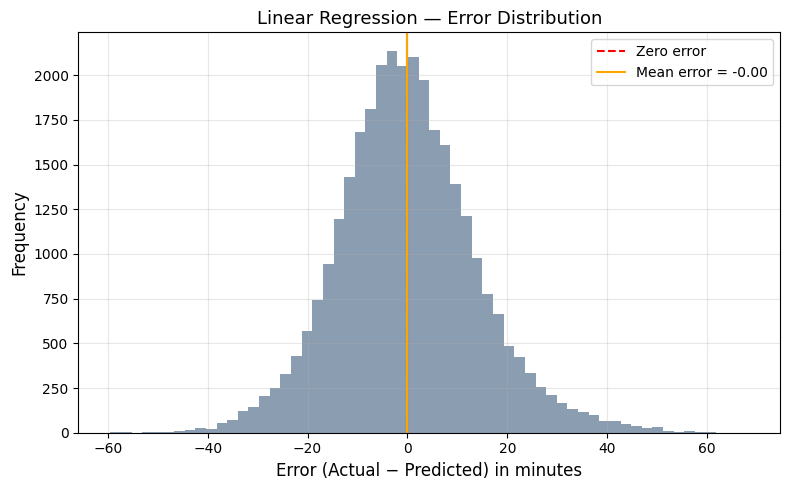

Saved: results/lr_error_distribution.png


In [15]:
# ── Linear Regression: Error Distribution ────────────────────────────────────
plt.figure(figsize=(8, 5))
plt.hist(residuals_lr, bins=60, color='#778CA3', alpha=0.85, edgecolor='none')
plt.axvline(0, color='red', linestyle='--', linewidth=1.5, label='Zero error')
plt.axvline(residuals_lr.mean(), color='orange', linestyle='-', linewidth=1.5,
            label=f'Mean error = {residuals_lr.mean():.2f}')
plt.xlabel('Error (Actual − Predicted) in minutes', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.title('Linear Regression — Error Distribution', fontsize=13)
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig('results/lr_error_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: results/lr_error_distribution.png")


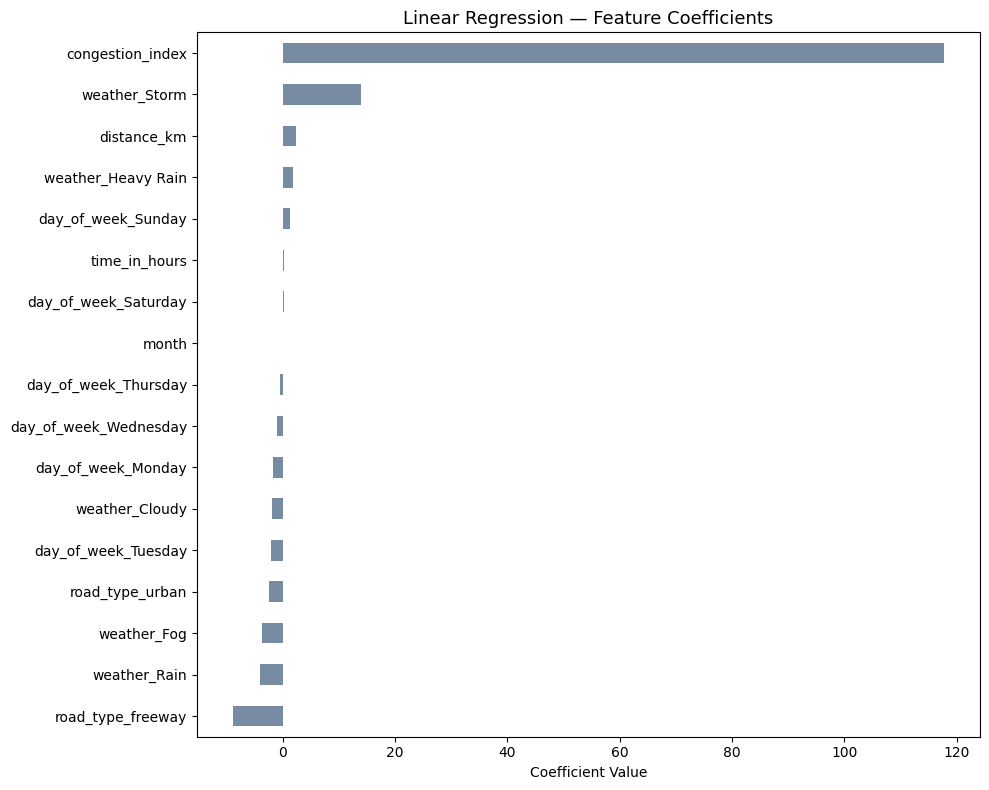

Saved: results/lr_feature_coefficients.png


In [16]:
# ── Linear Regression: Feature Coefficients ──────────────────────────────────
plt.figure(figsize=(10, 8))
pd.Series(lr.coef_, index=X_train.columns).sort_values().plot(kind='barh', color='#778CA3')
plt.title('Linear Regression — Feature Coefficients', fontsize=13)
plt.xlabel('Coefficient Value'); plt.tight_layout()
plt.savefig('results/lr_feature_coefficients.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: results/lr_feature_coefficients.png")


# Results & Analysis — Gradient Boosting

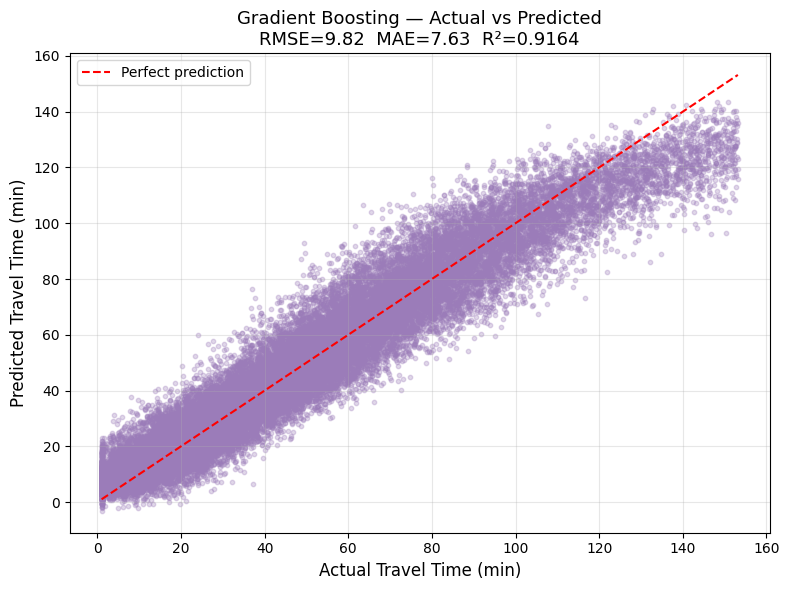

Saved: results/gb_actual_vs_predicted.png


In [17]:
# ── Gradient Boosting: Actual vs Predicted ────────────────────────────────────
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_gb, alpha=0.3, s=10, color='#9B7CB9')
mn, mx = y_test.min(), y_test.max()
plt.plot([mn, mx], [mn, mx], 'r--', linewidth=1.5, label='Perfect prediction')
plt.xlabel('Actual Travel Time (min)', fontsize=12)
plt.ylabel('Predicted Travel Time (min)', fontsize=12)
plt.title(f'Gradient Boosting — Actual vs Predicted\nRMSE={test_rmse_gb:.2f}  MAE={test_mae_gb:.2f}  R²={test_r2_gb:.4f}', fontsize=13)
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig('results/gb_actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: results/gb_actual_vs_predicted.png")


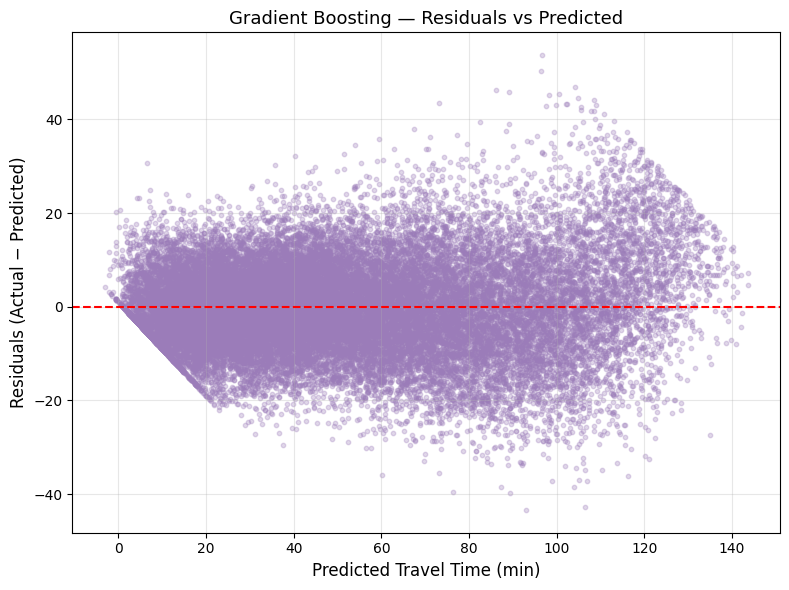

Saved: results/gb_residuals.png


In [18]:
# ── Gradient Boosting: Residuals ──────────────────────────────────────────────
residuals_gb = y_test - y_pred_gb
plt.figure(figsize=(8, 6))
plt.scatter(y_pred_gb, residuals_gb, alpha=0.3, s=10, color='#9B7CB9')
plt.axhline(0, color='red', linestyle='--', linewidth=1.5)
plt.xlabel('Predicted Travel Time (min)', fontsize=12)
plt.ylabel('Residuals (Actual − Predicted)', fontsize=12)
plt.title('Gradient Boosting — Residuals vs Predicted', fontsize=13)
plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig('results/gb_residuals.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: results/gb_residuals.png")


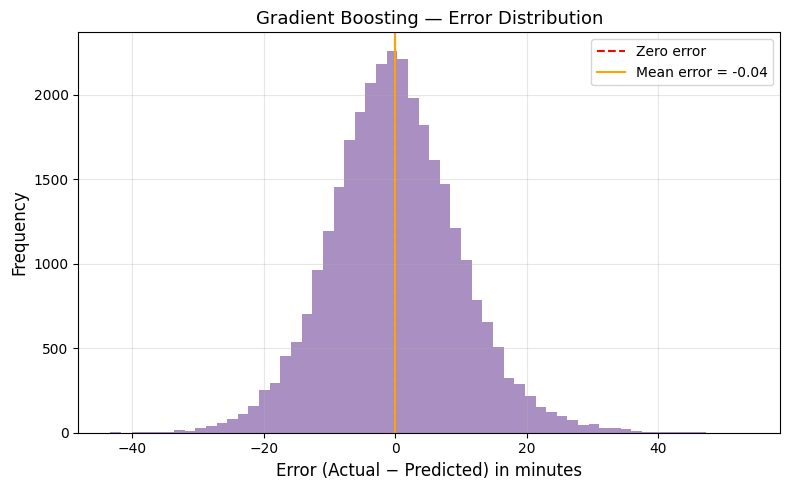

Saved: results/gb_error_distribution.png


In [19]:
# ── Gradient Boosting: Error Distribution ─────────────────────────────────────
plt.figure(figsize=(8, 5))
plt.hist(residuals_gb, bins=60, color='#9B7CB9', alpha=0.85, edgecolor='none')
plt.axvline(0, color='red', linestyle='--', linewidth=1.5, label='Zero error')
plt.axvline(residuals_gb.mean(), color='orange', linestyle='-', linewidth=1.5,
            label=f'Mean error = {residuals_gb.mean():.2f}')
plt.xlabel('Error (Actual − Predicted) in minutes', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.title('Gradient Boosting — Error Distribution', fontsize=13)
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig('results/gb_error_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: results/gb_error_distribution.png")


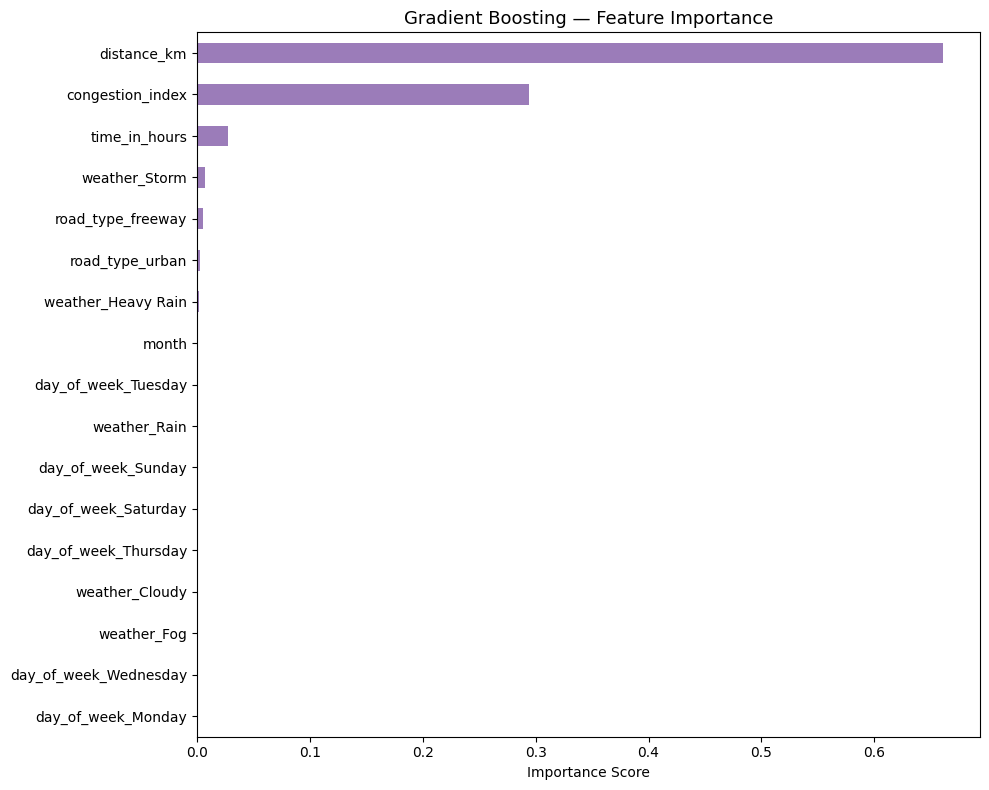

Saved: results/gb_feature_importance.png


In [20]:
# ── Gradient Boosting: Feature Importance ────────────────────────────────────
plt.figure(figsize=(10, 8))
pd.Series(gb.feature_importances_, index=X_train.columns).sort_values().plot(kind='barh', color='#9B7CB9')
plt.title('Gradient Boosting — Feature Importance', fontsize=13)
plt.xlabel('Importance Score'); plt.tight_layout()
plt.savefig('results/gb_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: results/gb_feature_importance.png")


# Results & Analysis — Random Forest

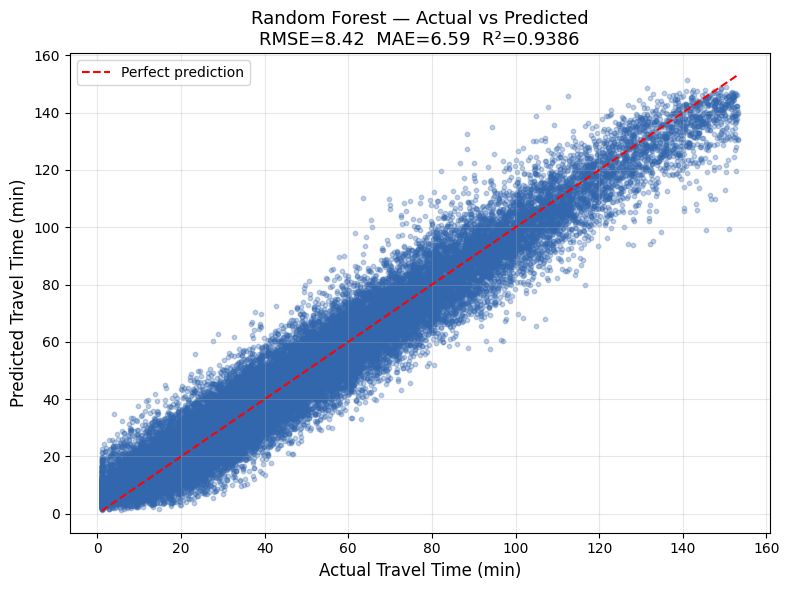

Saved: results/rf_actual_vs_predicted.png


In [21]:
# ── Random Forest: Actual vs Predicted ───────────────────────────────────────
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_test_pred, alpha=0.3, s=10, color='#3266AD')
mn, mx = y_test.min(), y_test.max()
plt.plot([mn, mx], [mn, mx], 'r--', linewidth=1.5, label='Perfect prediction')
plt.xlabel('Actual Travel Time (min)', fontsize=12)
plt.ylabel('Predicted Travel Time (min)', fontsize=12)
plt.title(f'Random Forest — Actual vs Predicted\nRMSE={test_rmse:.2f}  MAE={test_mae:.2f}  R²={test_r2:.4f}', fontsize=13)
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig('results/rf_actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: results/rf_actual_vs_predicted.png")


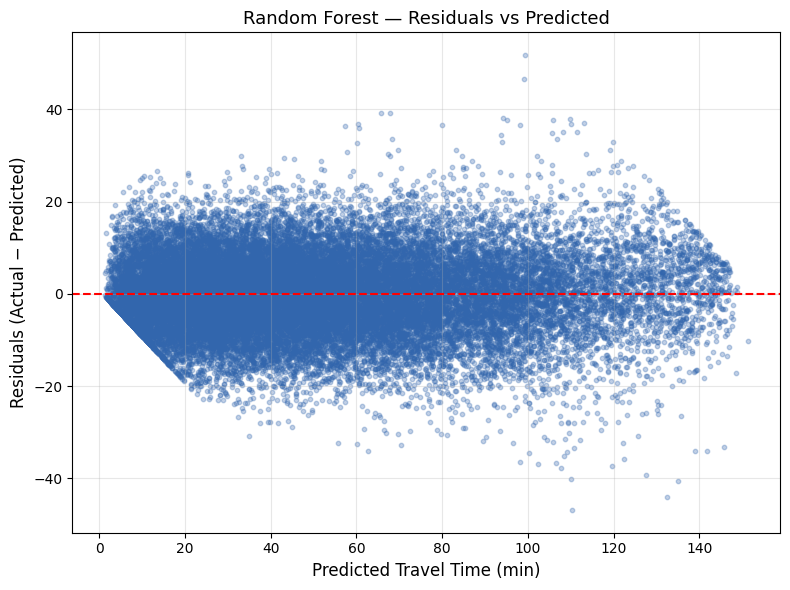

Saved: results/rf_residuals.png


In [22]:
# ── Random Forest: Residuals ──────────────────────────────────────────────────
residuals_rf = y_test - y_test_pred
plt.figure(figsize=(8, 6))
plt.scatter(y_test_pred, residuals_rf, alpha=0.3, s=10, color='#3266AD')
plt.axhline(0, color='red', linestyle='--', linewidth=1.5)
plt.xlabel('Predicted Travel Time (min)', fontsize=12)
plt.ylabel('Residuals (Actual − Predicted)', fontsize=12)
plt.title('Random Forest — Residuals vs Predicted', fontsize=13)
plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig('results/rf_residuals.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: results/rf_residuals.png")


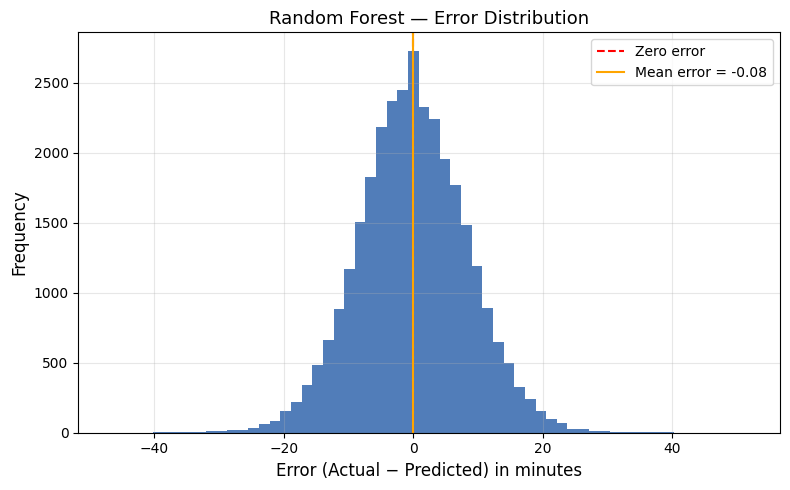

Saved: results/rf_error_distribution.png


In [23]:
# ── Random Forest: Error Distribution ────────────────────────────────────────
plt.figure(figsize=(8, 5))
plt.hist(residuals_rf, bins=60, color='#3266AD', alpha=0.85, edgecolor='none')
plt.axvline(0, color='red', linestyle='--', linewidth=1.5, label='Zero error')
plt.axvline(residuals_rf.mean(), color='orange', linestyle='-', linewidth=1.5,
            label=f'Mean error = {residuals_rf.mean():.2f}')
plt.xlabel('Error (Actual − Predicted) in minutes', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.title('Random Forest — Error Distribution', fontsize=13)
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig('results/rf_error_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: results/rf_error_distribution.png")


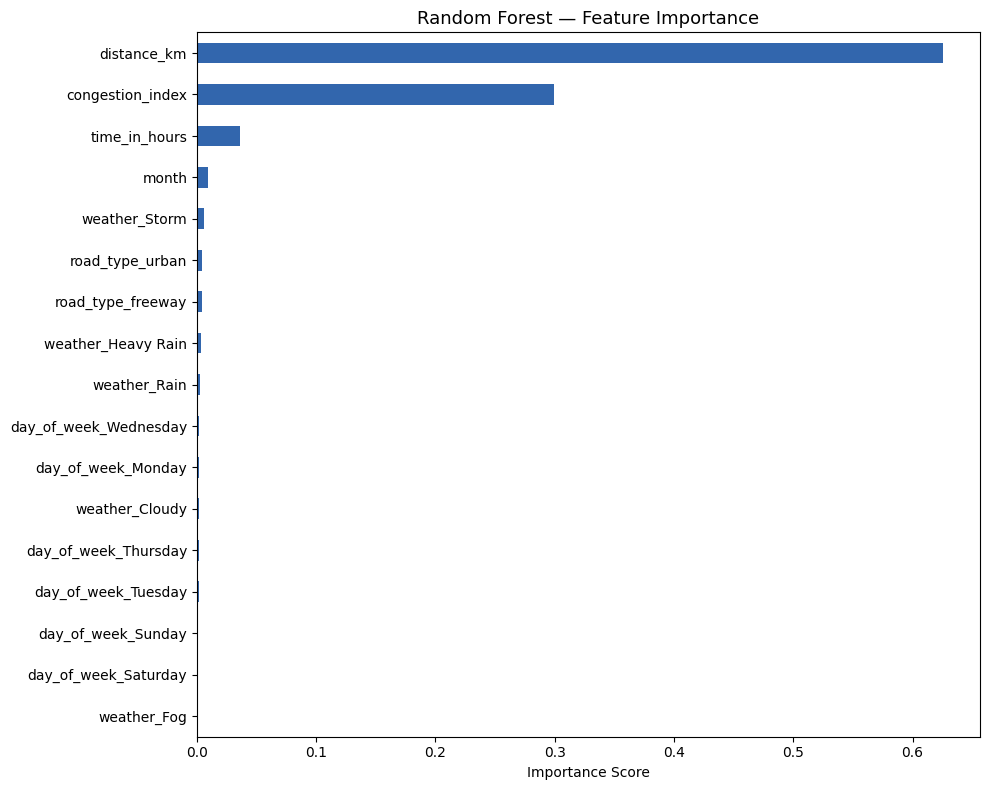

Saved: results/rf_feature_importance.png


In [24]:
# ── Random Forest: Feature Importance ────────────────────────────────────────
plt.figure(figsize=(10, 8))
pd.Series(model.feature_importances_, index=X_train.columns).sort_values().plot(kind='barh', color='#3266AD')
plt.title('Random Forest — Feature Importance', fontsize=13)
plt.xlabel('Importance Score'); plt.tight_layout()
plt.savefig('results/rf_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: results/rf_feature_importance.png")


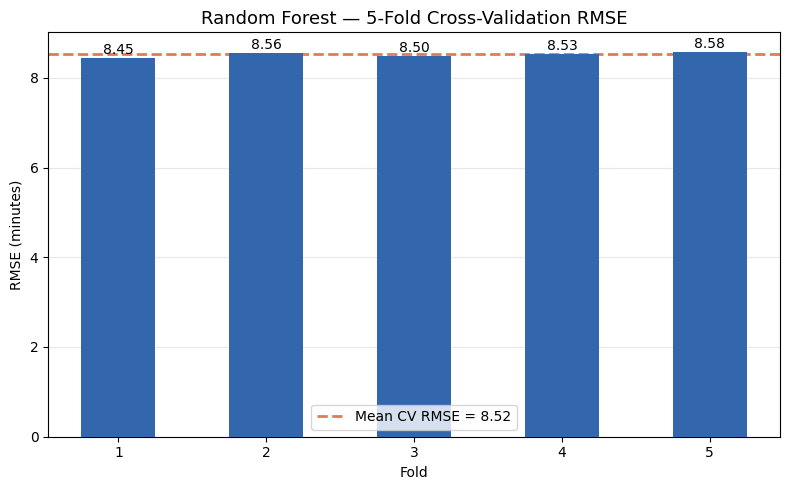

Saved: results/rf_cv_fold_scores.png


In [25]:
# ── Random Forest: CV Fold Scores ────────────────────────────────────────────
cv_fold_scores = -cross_val_score(model, X_train, y_train,
                                  cv=KFold(n_splits=5, shuffle=True, random_state=42),
                                  scoring='neg_root_mean_squared_error')
plt.figure(figsize=(8, 5))
plt.bar(range(1, 6), cv_fold_scores, color='#3266AD', zorder=3, width=0.5)
plt.axhline(cv_fold_scores.mean(), color='#E07B5A', linestyle='--', linewidth=2,
            label=f'Mean CV RMSE = {cv_fold_scores.mean():.2f}')
for i, v in enumerate(cv_fold_scores):
    plt.text(i+1, v+0.02, f'{v:.2f}', ha='center', va='bottom', fontsize=10)
plt.xlabel('Fold'); plt.ylabel('RMSE (minutes)')
plt.title('Random Forest — 5-Fold Cross-Validation RMSE', fontsize=13)
plt.legend(); plt.grid(axis='y', alpha=0.3); plt.tight_layout()
plt.savefig('results/rf_cv_fold_scores.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: results/rf_cv_fold_scores.png")


# Comparative Analysis — All Models

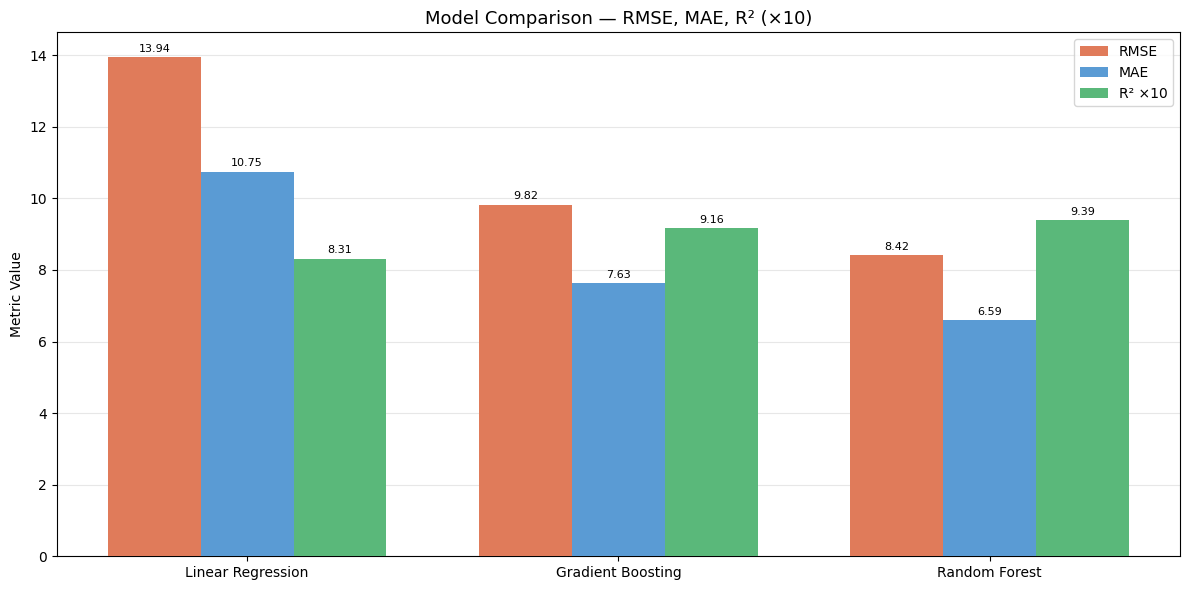

Saved: results/comparison_grouped_bar.png


In [26]:
# ── Grouped Metric Bar Chart ─────────────────────────────────────────────────
models    = ['Linear Regression', 'Gradient Boosting', 'Random Forest']
rmse_vals = [test_rmse_lr, test_rmse_gb, test_rmse]
mae_vals  = [test_mae_lr,  test_mae_gb,  test_mae]
r2_vals   = [test_r2_lr,   test_r2_gb,   test_r2]
colors    = ['#778CA3', '#9B7CB9', '#3266AD']

x, w = np.arange(3), 0.25
plt.figure(figsize=(12, 6))
b1 = plt.bar(x - w,   rmse_vals,               width=w, color='#E07B5A', label='RMSE', zorder=3)
b2 = plt.bar(x,       mae_vals,                width=w, color='#5A9BD4', label='MAE',  zorder=3)
b3 = plt.bar(x + w, [r*10 for r in r2_vals],   width=w, color='#5AB87A', label='R² ×10', zorder=3)
for bars in [b1, b2, b3]:
    for bar in bars:
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                 f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=8)
plt.xticks(x, models); plt.ylabel('Metric Value')
plt.title('Model Comparison — RMSE, MAE, R² (×10)', fontsize=13)
plt.legend(); plt.grid(axis='y', alpha=0.3); plt.tight_layout()
plt.savefig('results/comparison_grouped_bar.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: results/comparison_grouped_bar.png")


C:\Users\Ronish\AppData\Local\Temp\ipykernel_3952\1989519695.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(models, rotation=10, ha='right', fontsize=9)
C:\Users\Ronish\AppData\Local\Temp\ipykernel_3952\1989519695.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(models, rotation=10, ha='right', fontsize=9)
C:\Users\Ronish\AppData\Local\Temp\ipykernel_3952\1989519695.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(models, rotation=10, ha='right', fontsize=9)


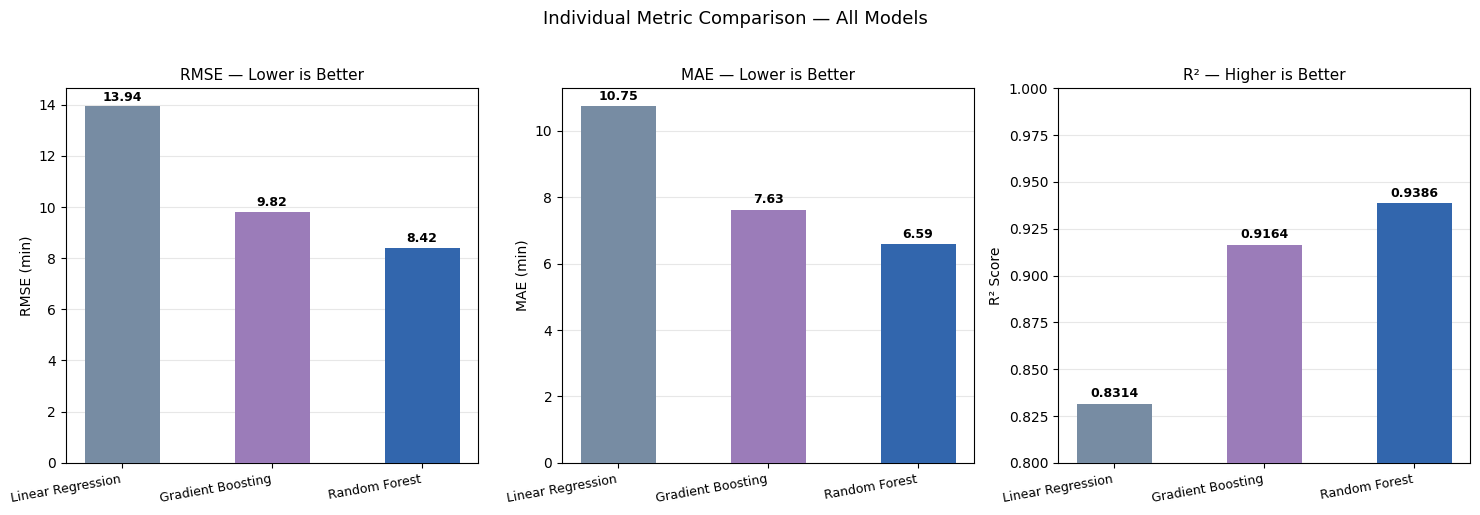

Saved: results/comparison_individual_metrics.png


In [27]:
# ── Individual RMSE / MAE / R² Bars ──────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (title, vals, ylabel, invert) in zip(axes, [
        ('RMSE — Lower is Better',  rmse_vals, 'RMSE (min)', False),
        ('MAE — Lower is Better',   mae_vals,  'MAE (min)',  False),
        ('R² — Higher is Better',   r2_vals,   'R² Score',   True)]):
    bars = ax.bar(models, vals, color=colors, zorder=3, width=0.5)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + (0.002 if invert else 0.1),
                f'{val:.4f}' if invert else f'{val:.2f}',
                ha='center', va='bottom', fontweight='bold', fontsize=9)
    ax.set_title(title, fontsize=11)
    ax.set_ylabel(ylabel)
    if invert: ax.set_ylim([0.8, 1.0])
    ax.set_xticklabels(models, rotation=10, ha='right', fontsize=9)
    ax.grid(axis='y', alpha=0.3); ax.set_axisbelow(True)

plt.suptitle('Individual Metric Comparison — All Models', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('results/comparison_individual_metrics.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: results/comparison_individual_metrics.png")


In [3]:
print('Linear Regression Performance:')
print(f'  Train RMSE: 10.34| Test RMSE: 13.94')
print(f'  Train MAE: 7.56 | Test MAE: 10.75')
print(f'  Train R²:   0.9023 | Test R²:   0.8314')

print()

print('Gradient Boosting Performance:')
print(f'  Train RMSE: 5.54| Test RMSE: 9.82')
print(f'  Train MAE:  3.67 | Test MAE:  7.63')
print(f'  Train R²:   0.9673  | Test R²:   0.9164')

print()



Linear Regression Performance:
  Train RMSE: 10.34| Test RMSE: 13.94
  Train MAE: 7.56 | Test MAE: 10.75
  Train R²:   0.9023 | Test R²:   0.8314

Gradient Boosting Performance:
  Train RMSE: 5.54| Test RMSE: 9.82
  Train MAE:  3.67 | Test MAE:  7.63
  Train R²:   0.9673  | Test R²:   0.9164



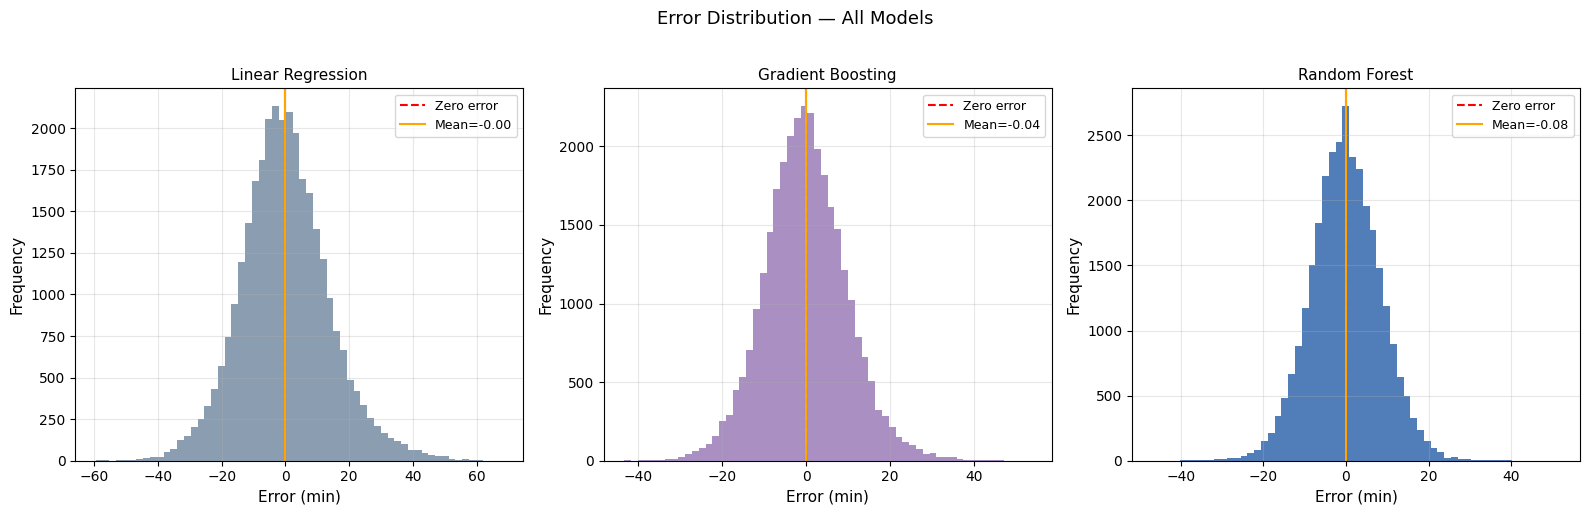

Saved: results/comparison_error_distribution.png


In [28]:
# ── Error Distribution Overlay — All 3 Models ────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, resid, col) in zip(axes, [
        ('Linear Regression',  residuals_lr, '#778CA3'),
        ('Gradient Boosting',  residuals_gb, '#9B7CB9'),
        ('Random Forest',      residuals_rf, '#3266AD')]):
    ax.hist(resid, bins=60, color=col, alpha=0.85, edgecolor='none')
    ax.axvline(0,           color='red',    linestyle='--', linewidth=1.5, label='Zero error')
    ax.axvline(resid.mean(),color='orange', linestyle='-',  linewidth=1.5,
               label=f'Mean={resid.mean():.2f}')
    ax.set_xlabel('Error (min)', fontsize=11)
    ax.set_ylabel('Frequency', fontsize=11)
    ax.set_title(name, fontsize=11)
    ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.suptitle('Error Distribution — All Models', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('results/comparison_error_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: results/comparison_error_distribution.png")


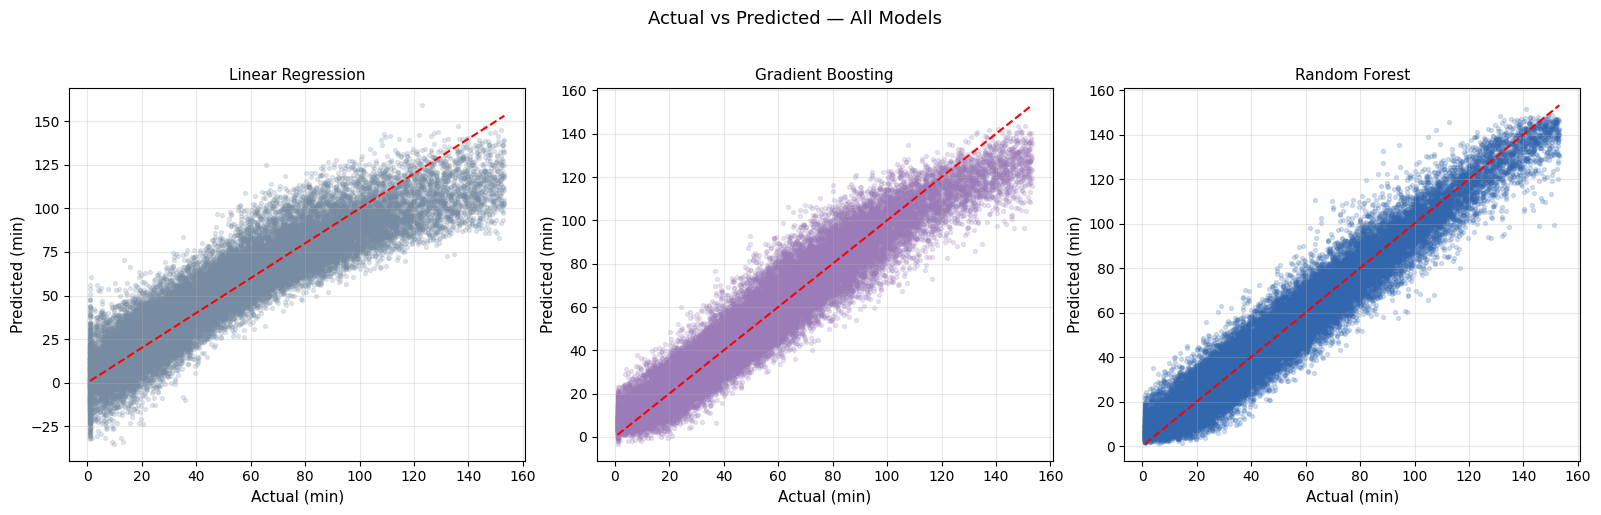

Saved: results/comparison_actual_vs_predicted.png


In [29]:
# ── Actual vs Predicted — All 3 Models Side by Side ──────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, preds, col) in zip(axes, [
        ('Linear Regression',  y_pred_lr,   '#778CA3'),
        ('Gradient Boosting',  y_pred_gb,   '#9B7CB9'),
        ('Random Forest',      y_test_pred, '#3266AD')]):
    ax.scatter(y_test, preds, alpha=0.2, s=8, color=col)
    mn, mx = y_test.min(), y_test.max()
    ax.plot([mn, mx], [mn, mx], 'r--', linewidth=1.5)
    ax.set_xlabel('Actual (min)', fontsize=11)
    ax.set_ylabel('Predicted (min)', fontsize=11)
    ax.set_title(name, fontsize=11)
    ax.grid(alpha=0.3)
plt.suptitle('Actual vs Predicted — All Models', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('results/comparison_actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: results/comparison_actual_vs_predicted.png")


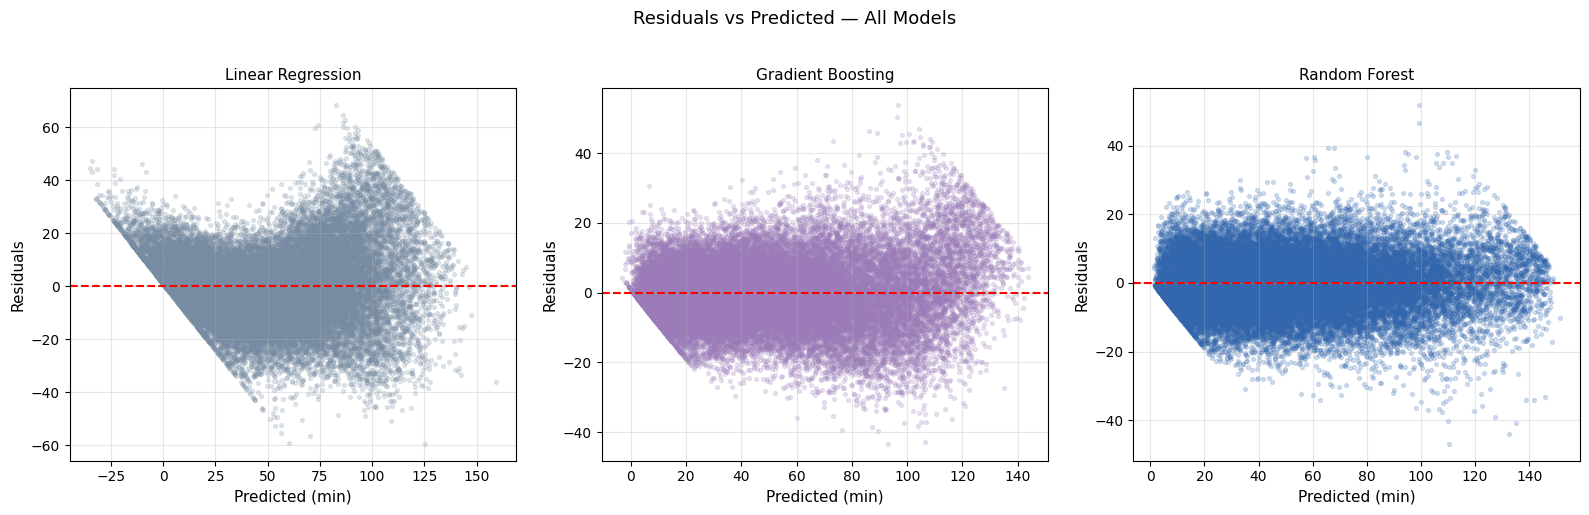

Saved: results/comparison_residuals.png


In [30]:
# ── Residuals — All 3 Models Side by Side ────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, preds, resid, col) in zip(axes, [
        ('Linear Regression',  y_pred_lr,   residuals_lr, '#778CA3'),
        ('Gradient Boosting',  y_pred_gb,   residuals_gb, '#9B7CB9'),
        ('Random Forest',      y_test_pred, residuals_rf, '#3266AD')]):
    ax.scatter(preds, resid, alpha=0.2, s=8, color=col)
    ax.axhline(0, color='red', linestyle='--', linewidth=1.5)
    ax.set_xlabel('Predicted (min)', fontsize=11)
    ax.set_ylabel('Residuals', fontsize=11)
    ax.set_title(name, fontsize=11)
    ax.grid(alpha=0.3)
plt.suptitle('Residuals vs Predicted — All Models', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('results/comparison_residuals.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: results/comparison_residuals.png")


C:\Users\Ronish\AppData\Local\Temp\ipykernel_3952\4200519416.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([cv_lr_scores, cv_gb_scores, cv_rf_scores],


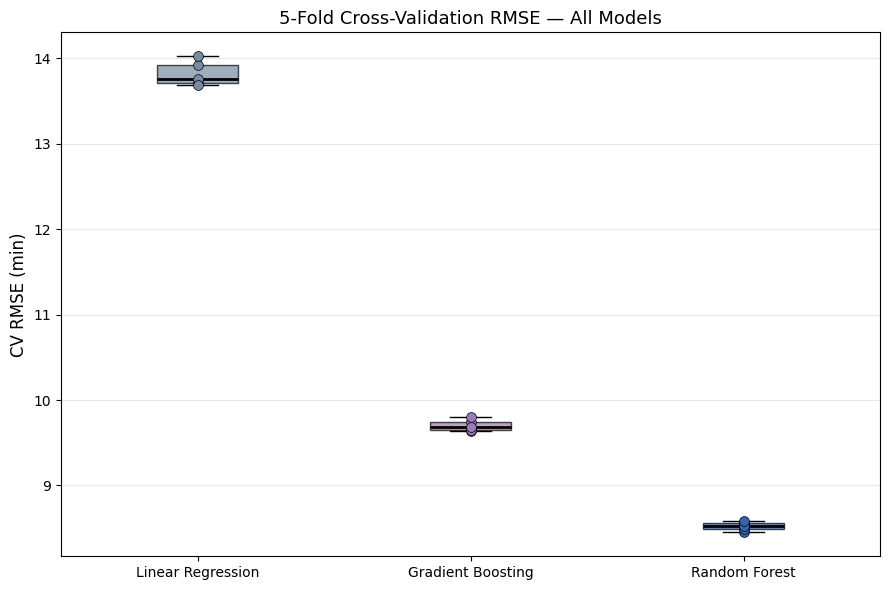

Saved: results/comparison_cv_boxplot.png


In [31]:
# ── CV Box Plot — All 3 Models ────────────────────────────────────────────────
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_lr_scores = -cross_val_score(lr,    X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error')
cv_gb_scores = -cross_val_score(gb,    X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error')
cv_rf_scores = -cross_val_score(model, X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error')

fig, ax = plt.subplots(figsize=(9, 6))
bp = ax.boxplot([cv_lr_scores, cv_gb_scores, cv_rf_scores],
                labels=['Linear Regression', 'Gradient Boosting', 'Random Forest'],
                patch_artist=True,
                medianprops=dict(color='black', linewidth=2))
for patch, col in zip(bp['boxes'], ['#778CA3', '#9B7CB9', '#3266AD']):
    patch.set_facecolor(col); patch.set_alpha(0.7)
for i, (scores, col) in enumerate(zip([cv_lr_scores, cv_gb_scores, cv_rf_scores],
                                       ['#778CA3', '#9B7CB9', '#3266AD']), start=1):
    ax.scatter([i]*len(scores), scores, color=col, zorder=5, s=50,
               edgecolors='black', linewidths=0.5)
ax.set_ylabel('CV RMSE (min)', fontsize=12)
ax.set_title('5-Fold Cross-Validation RMSE — All Models', fontsize=13)
ax.grid(axis='y', alpha=0.3); plt.tight_layout()
plt.savefig('results/comparison_cv_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: results/comparison_cv_boxplot.png")


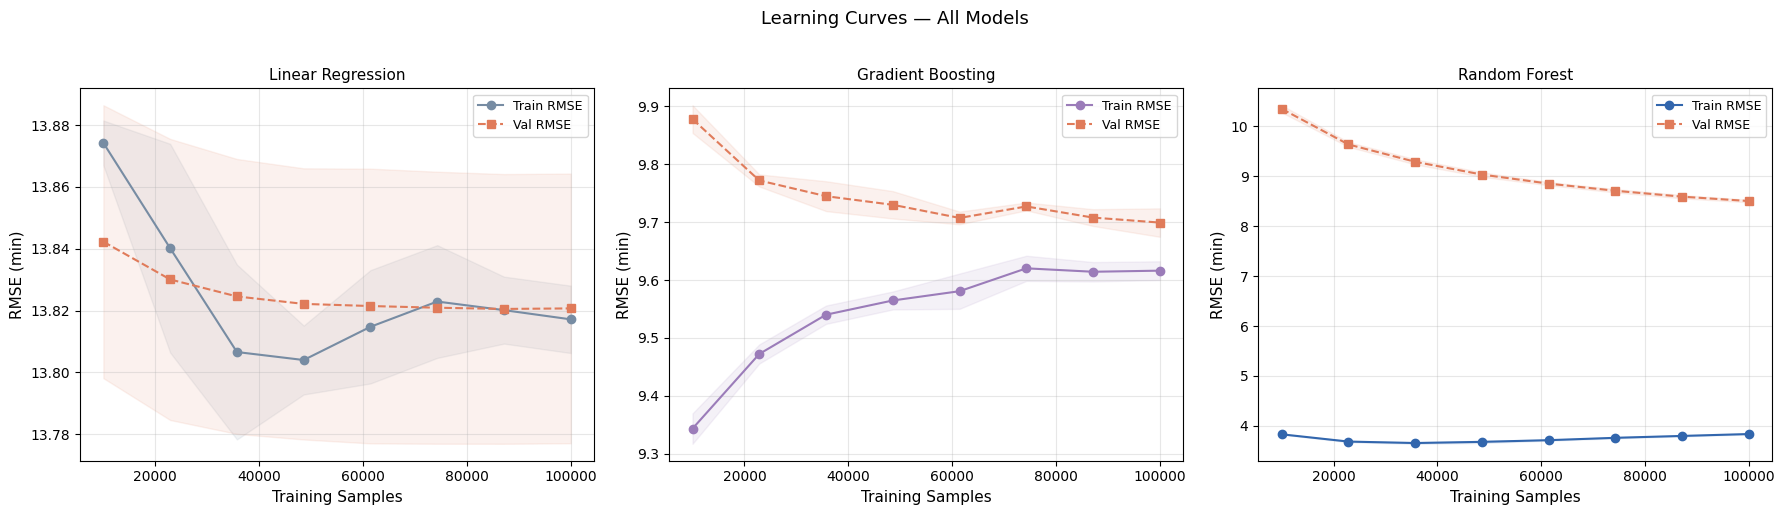

Saved: results/comparison_learning_curves.png


In [32]:
# ── Learning Curves — All 3 Models ───────────────────────────────────────────
from sklearn.model_selection import learning_curve

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, estimator, col) in zip(axes, [
        ('Linear Regression',  lr,    '#778CA3'),
        ('Gradient Boosting',  gb,    '#9B7CB9'),
        ('Random Forest',      model, '#3266AD')]):
    train_sizes, train_scores, val_scores = learning_curve(
        estimator, X_train, y_train,
        cv=5, scoring='neg_root_mean_squared_error',
        train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1)
    train_mean = -train_scores.mean(axis=1)
    val_mean   = -val_scores.mean(axis=1)
    train_std  =  train_scores.std(axis=1)
    val_std    =  val_scores.std(axis=1)
    ax.plot(train_sizes, train_mean, 'o-',  color=col,       label='Train RMSE')
    ax.plot(train_sizes, val_mean,   's--', color='#E07B5A', label='Val RMSE')
    ax.fill_between(train_sizes, train_mean-train_std, train_mean+train_std, alpha=0.1, color=col)
    ax.fill_between(train_sizes, val_mean-val_std,     val_mean+val_std,     alpha=0.1, color='#E07B5A')
    ax.set_xlabel('Training Samples', fontsize=11)
    ax.set_ylabel('RMSE (min)', fontsize=11)
    ax.set_title(name, fontsize=11)
    ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.suptitle('Learning Curves — All Models', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('results/comparison_learning_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: results/comparison_learning_curves.png")


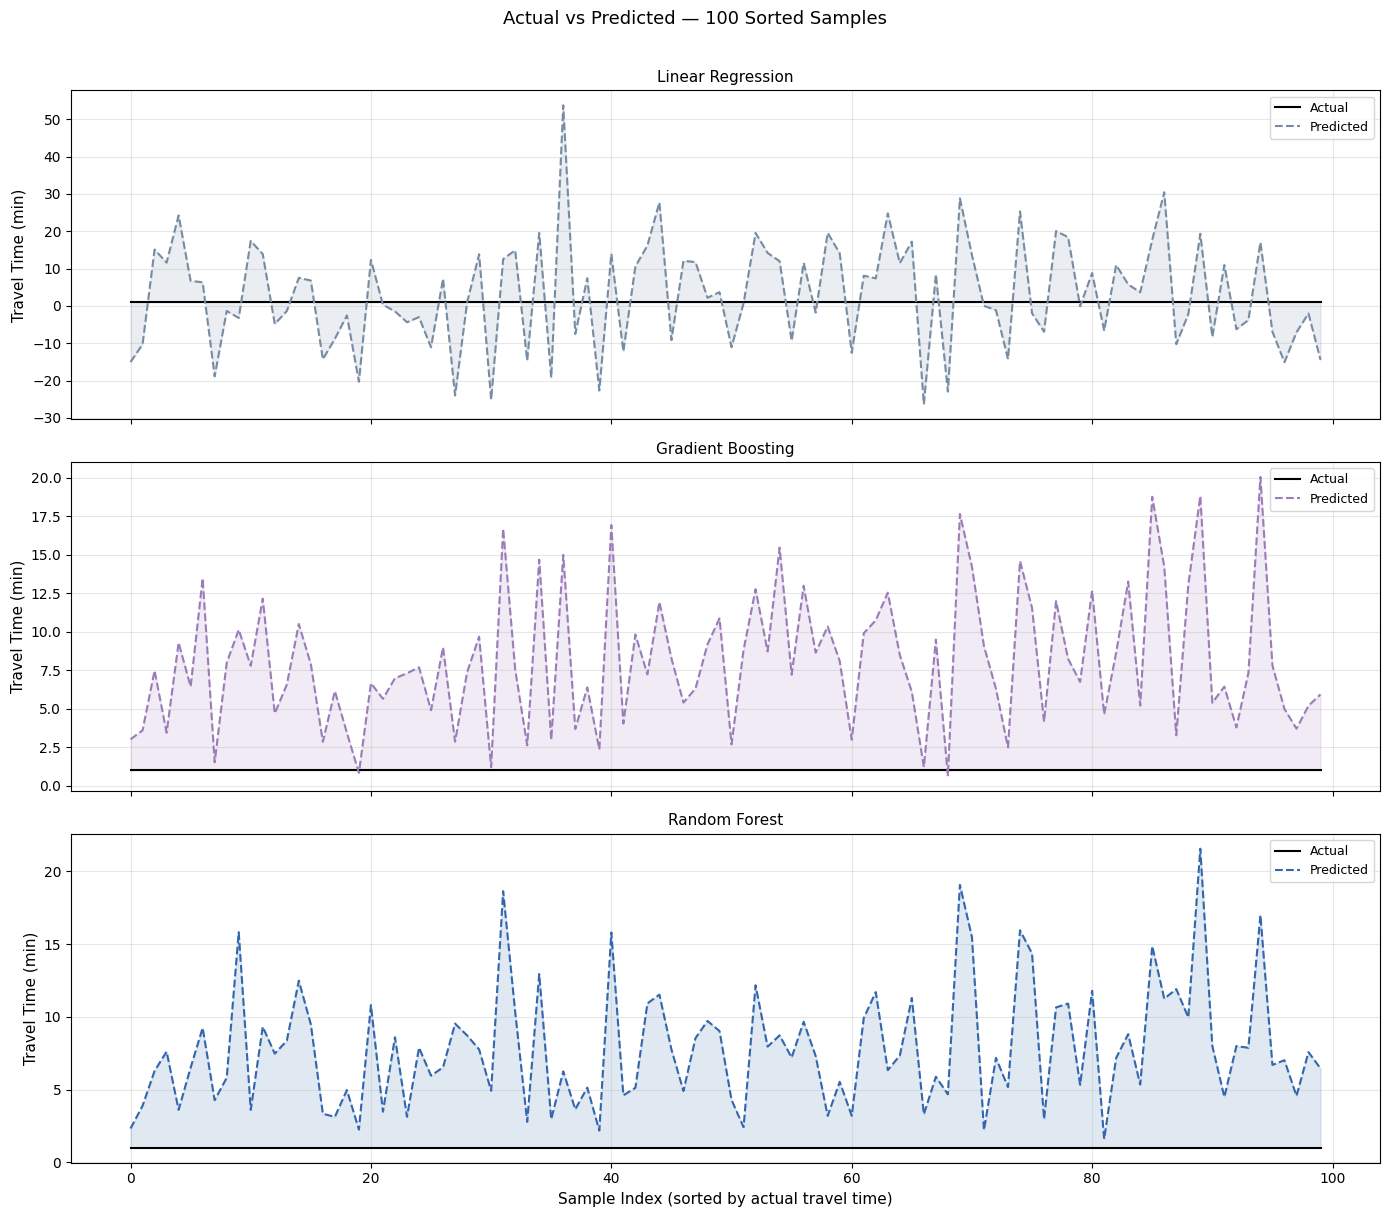

Saved: results/comparison_line_plot.png


In [33]:
# ── Actual vs Predicted Line Plot — 100 Sorted Samples ───────────────────────
sample_idx = np.argsort(y_test.values)[:100]
fig, axes  = plt.subplots(3, 1, figsize=(14, 12), sharex=True)
for ax, (name, preds, col) in zip(axes, [
        ('Linear Regression',  y_pred_lr,   '#778CA3'),
        ('Gradient Boosting',  y_pred_gb,   '#9B7CB9'),
        ('Random Forest',      y_test_pred, '#3266AD')]):
    actual = y_test.values[sample_idx]
    pred   = preds[sample_idx]
    ax.plot(range(100), actual, color='black', linewidth=1.5, label='Actual')
    ax.plot(range(100), pred,   color=col,     linewidth=1.5, label='Predicted', linestyle='--')
    ax.fill_between(range(100), actual, pred, alpha=0.15, color=col)
    ax.set_ylabel('Travel Time (min)', fontsize=11)
    ax.set_title(name, fontsize=11)
    ax.legend(fontsize=9); ax.grid(alpha=0.3)
axes[-1].set_xlabel('Sample Index (sorted by actual travel time)', fontsize=11)
plt.suptitle('Actual vs Predicted — 100 Sorted Samples', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('results/comparison_line_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: results/comparison_line_plot.png")


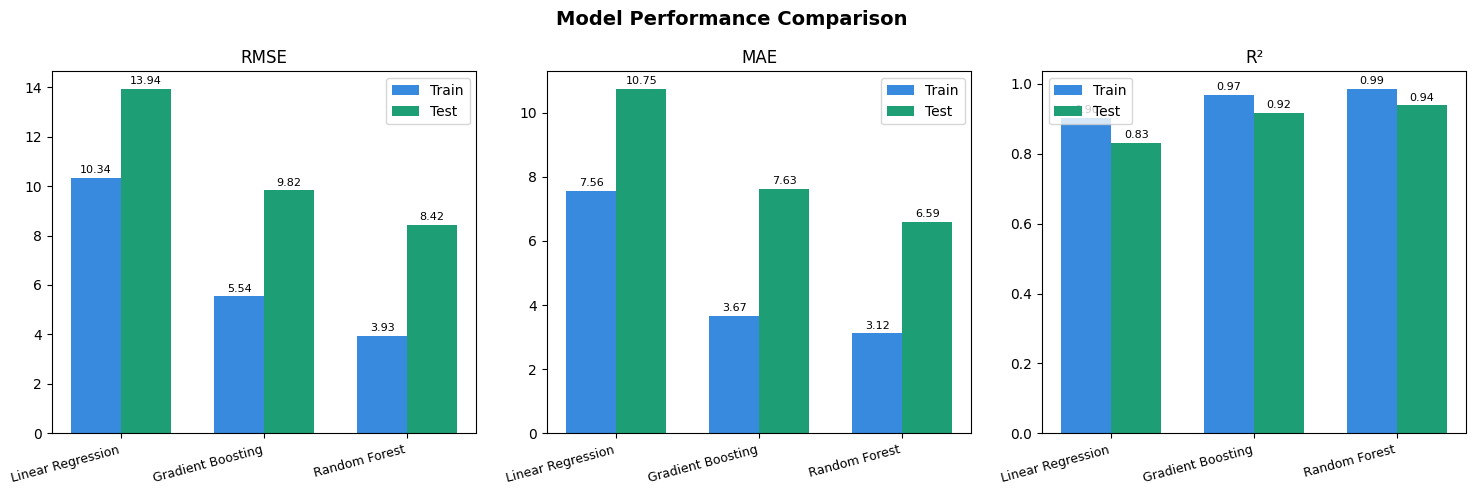

In [6]:
import matplotlib.pyplot as plt
import numpy as np
 
models = ['Linear Regression', 'Gradient Boosting', 'Random Forest']
 

 
x = np.arange(len(models))
width = 0.35
 
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Model Performance Comparison', fontsize=14, fontweight='bold')
 
metrics = [
    ('RMSE', train_rmse, test_rmse),
    ('MAE',  train_mae,  test_mae),
    ('R²',   train_r2,   test_r2),
]
 
for ax, (title, train, test) in zip(axes, metrics):
    bars1 = ax.bar(x - width/2, train, width, label='Train', color='#378ADD')
    bars2 = ax.bar(x + width/2, test,  width, label='Test',  color='#1D9E75')
    ax.set_title(title)
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=15, ha='right', fontsize=9)
    ax.legend()
    ax.bar_label(bars1, fmt='%.2f', fontsize=8, padding=2)
    ax.bar_label(bars2, fmt='%.2f', fontsize=8, padding=2)
 
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()